In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.metrics import  confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

from sklearn.metrics import classification_report
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score



from sklearn.metrics import (precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, roc_auc_score,
                             precision_recall_curve)

## Punto 1

In [ ]:
df = pd.read_csv("C:\\Users\\soporte.sistemas\\RepoLocal\\Unicafam\\parcial2_IA2\\data\\data.csv", encoding = "latin-1", sep = ";")
df.head()

,ï»¿Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [7]:
df["Target"].unique()

<StringArray>
['Dropout', 'Graduate', 'Enrolled']
Length: 3, dtype: str

In [8]:
df.describe()

,ï»¿Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   ï»¿Marital status                               4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [10]:
df.isnull().sum()

ï»¿Marital status                                 0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [11]:
hay_duplicados = df.duplicated().any()
print(hay_duplicados)

False


<Axes: xlabel='Target', ylabel='count'>

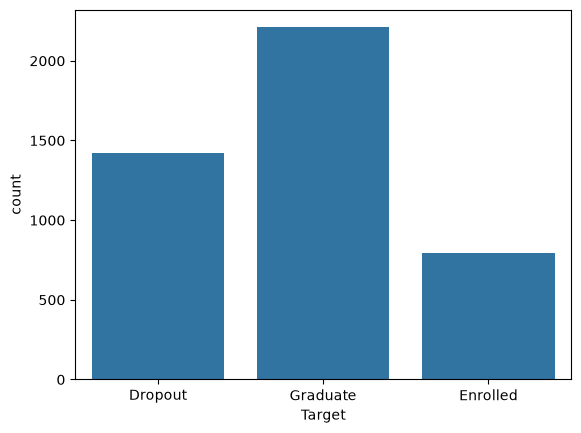

In [12]:
sns.countplot(x = "Target", data = df)

Vemos que el dataset está limpio. No tiene nulos ni duplicados, así que no hace falta imputar nada, desbalance importante ya que la variable Enrolled presenta una cantidad de datos significativamente menor, debido a esto se hace necesario balancear los datos, para que la evaluacion sea mas pareja

In [13]:
under_sampling = RandomUnderSampler(random_state=42)

x = df.drop("Target", axis = 1)
y = df.Target

In [14]:
x_under, y_under = under_sampling.fit_resample(x,y)

<Axes: xlabel='Target', ylabel='count'>

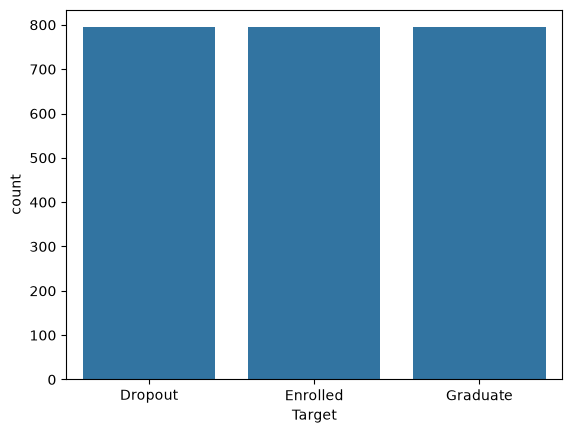

In [15]:
sns.countplot(x = y_under)

In [16]:
mapa = {"Dropout":1, "Graduate":2, "Enrolled":3}
y_under = y_under.map(mapa).astype(int)
y_under.unique()

array([1, 3, 2])

In [17]:
x_under_encoded = pd.get_dummies(x_under,drop_first=True,dtype=int)

In [18]:
df_new = x_under_encoded.copy()
df_new["Target"] = y_under

print(df_new.dtypes)

ï»¿Marital status                                   int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance\t                        int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Admission grade                                   float64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender        

In [19]:
df_new.head()

,ï»¿Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
178,1,1,5,9853,1,1,141.0,1,37,19,...,0,6,12,5,10.4,0,9.4,-0.8,-3.12,1
989,1,17,2,9085,1,1,133.1,1,19,38,...,0,6,19,2,13.5,0,12.4,0.5,1.79,1
2273,2,1,4,8014,0,1,140.0,1,34,34,...,0,6,0,0,0.0,0,9.4,-0.8,-3.12,1
3253,1,44,1,9130,1,39,130.0,1,1,3,...,1,6,12,1,13.0,0,13.9,-0.3,0.79,1
1294,2,39,1,9003,1,1,168.0,1,1,41,...,0,6,0,0,0.0,0,12.4,0.5,1.79,1


c:\Users\soporte.sistemas\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.draw()


<Axes: >

C:\Users\soporte.sistemas\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


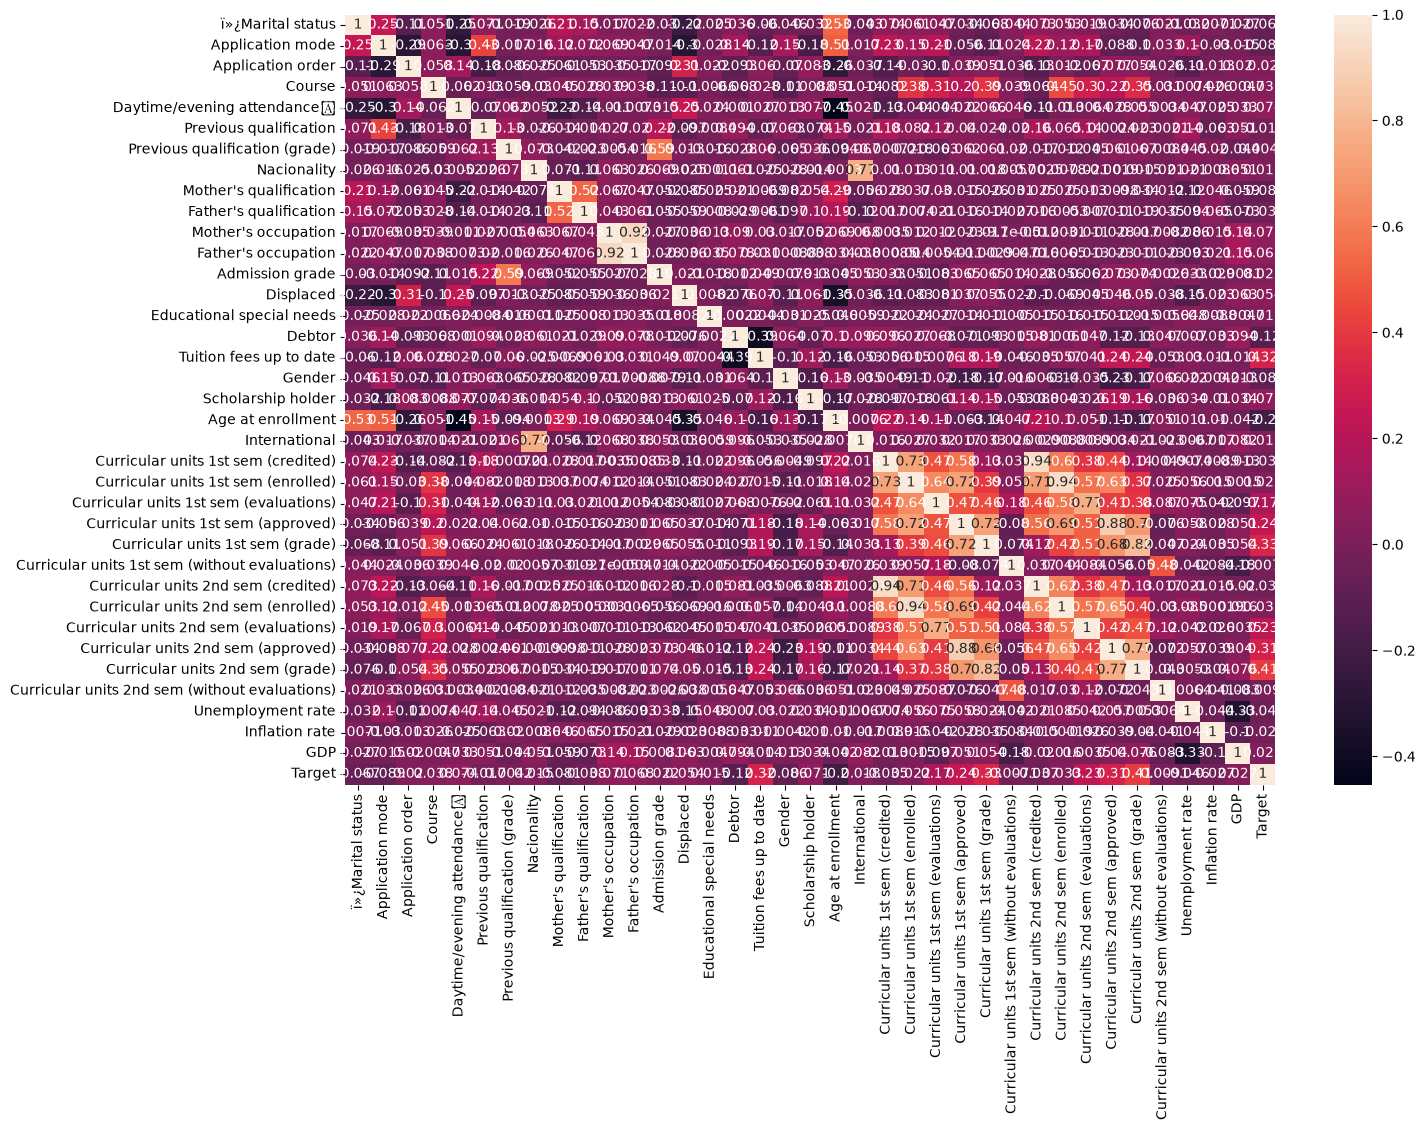

In [20]:
plt.figure(figsize=(15,10))
sns.heatmap(df_new.corr(), annot = True)

In [21]:
x_train, x_test, y_train, y_test = train_test_split(x_under_encoded,y_under,test_size=0.3,random_state=42,stratify=y_under)

In [22]:
scalet = StandardScaler()

X_train = scalet.fit_transform(x_train)
X_test = scalet.fit_transform(x_test)

In [49]:
x_test

,ï»¿Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
1742,1,1,1,9130,1,1,121.0,1,3,19,...,0,0,6,7,5,13.333333,0,15.5,2.8,-4.06
2566,1,17,1,9500,1,1,142.0,1,38,1,...,0,0,8,9,8,14.788889,0,12.4,0.5,1.79
2941,2,39,2,9556,1,1,133.1,105,1,3,...,0,0,8,8,8,12.300000,0,12.4,0.5,1.79
467,1,43,6,9238,1,1,129.0,1,34,34,...,0,11,13,15,13,13.266667,0,9.4,-0.8,-3.12
2412,2,39,2,9991,0,1,150.0,1,37,37,...,0,1,5,10,4,12.500000,0,9.4,-0.8,-3.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123,1,1,1,9670,1,1,131.0,1,38,38,...,0,0,5,5,5,14.200000,0,9.4,-0.8,-3.12
3075,1,1,1,9670,1,1,132.0,1,4,2,...,0,0,6,10,5,11.600000,0,13.9,-0.3,0.79
916,2,39,1,9991,0,1,147.0,1,34,34,...,0,0,5,5,0,0.000000,0,7.6,2.6,0.32
3794,1,17,1,9119,1,1,130.0,1,19,19,...,0,0,5,10,2,12.000000,3,7.6,2.6,0.32


In [50]:
def regresion_logistica(solver_, multiclass_, C_):
  model = LogisticRegression(random_state=42, solver=solver_, multi_class= multiclass_, C= C_)
  return model

In [51]:
# solvers = ["lbfgs", "newton-cg", "sag", "saga"]

model = regresion_logistica("lbfgs", "multinomial", 1)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(confusion_matrix(y_test, predictions))
print(accuracy_score(y_test, predictions))

[[170  18  50]
 [  4 200  34]
 [ 38  62 139]]
0.7118881118881119


c:\Users\soporte.sistemas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\soporte.sistemas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [41]:
model = regresion_logistica("newton-cg", "multinomial", 1)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(confusion_matrix(y_test, predictions))
print(accuracy_score(y_test, predictions))

[[170  18  50]
 [  4 200  34]
 [ 38  62 139]]
0.7118881118881119


c:\Users\soporte.sistemas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [42]:
model = regresion_logistica("sag", "multinomial", 1)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(confusion_matrix(y_test, predictions))
print(accuracy_score(y_test, predictions))

[[170  18  50]
 [  4 200  34]
 [ 38  62 139]]
0.7118881118881119


c:\Users\soporte.sistemas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [43]:
model = regresion_logistica("saga", "multinomial", 1)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(confusion_matrix(y_test, predictions))
print(accuracy_score(y_test, predictions))

[[170  18  50]
 [  4 200  34]
 [ 38  62 139]]
0.7118881118881119


c:\Users\soporte.sistemas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\soporte.sistemas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


              precision    recall  f1-score   support

     Dropout       0.80      0.71      0.76       238
    Graduate       0.71      0.84      0.77       238
    Enrolled       0.62      0.58      0.60       239

    accuracy                           0.71       715
   macro avg       0.71      0.71      0.71       715
weighted avg       0.71      0.71      0.71       715



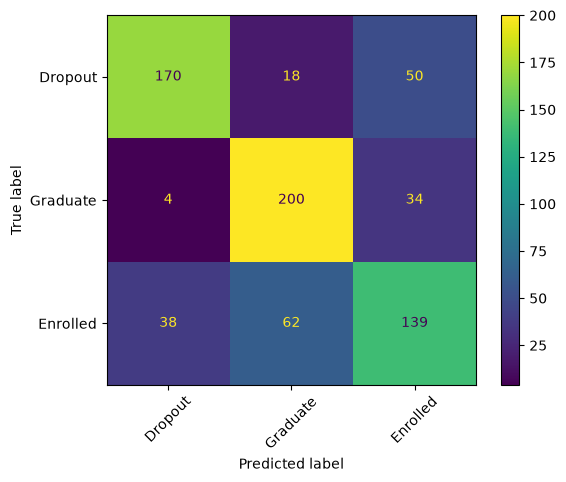

In [26]:
nombres = ["Dropout", "Graduate", "Enrolled"]

print(classification_report(y_test, predictions, target_names=nombres))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=nombres, xticks_rotation=45
)
plt.show()

In [ ]:
coef = pd.DataFrame(model.coef_, columns=x_train.columns, index=nombres)
print(coef.round(2))

          ï»¿Marital status  Application mode  Application order  Course  \
Dropout               -0.08              0.04               0.05    0.22   
Graduate               0.00             -0.11              -0.04   -0.21   
Enrolled               0.08              0.07              -0.01   -0.01   

          Daytime/evening attendance\t  Previous qualification  \
Dropout                          -0.02                   -0.10   
Graduate                          0.01                    0.18   
Enrolled                          0.01                   -0.08   

          Previous qualification (grade)  Nacionality  Mother's qualification  \
Dropout                             0.11         0.08                    0.08   
Graduate                           -0.03        -0.08                    0.07   
Enrolled                           -0.08        -0.00                   -0.16   

          Father's qualification  ...  \
Dropout                    -0.02  ...   
Graduate               

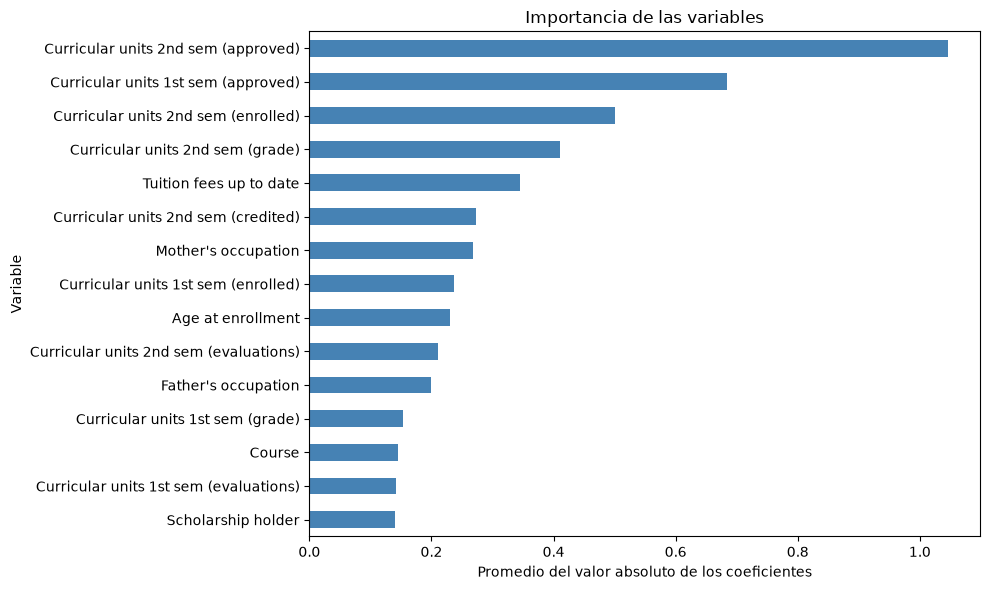

In [35]:
importancia = coef.abs().mean(axis=0).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
importancia.sort_values().plot(kind="barh", color="steelblue")
plt.title("Importancia de las variables")
plt.xlabel("Promedio del valor absoluto de los coeficientes")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

Desicion: Muchas Variables con bastante correlación\
Alternativas Consideradas: Considere empzar a eliminar sin embargo a futuro podria ver la importancia de las variables ahi si podria tomar la desicion\
Eleccion: Deajar todas las variables entrenar y evaluar, validar las importancia de las variables para saber cuales eliminar en este caso

Desicion: Desabalance de clases\
Alternetivas: No balancearlas\
Eleccion: Balancearlas ya que habia mucha diferencia de una a otra, con el fin de que la prueba fuera lo mas homogeneo posible

Desicion: Solvers\
Alterativas: lbfgs, sag, saga y newton-cg\
Elecion: Elegi saga porque realmente con los demas da lo mismo no cambia mucho

## Punto 2

In [ ]:
X_bal, y_bal = RandomUnderSampler(random_state=42).fit_resample(X, y)
X_esc = StandardScaler().fit_transform(X_bal)
X_train, X_test, y_train, y_test = train_test_split(X_esc, y_bal, test_size=0.2) # , random_state=42, stratify=y_bal

resultados = {}
for s in ["lbfgs", "newton-cg", "sag", "saga"]:
    try:
        m = LogisticRegression(solver=s, multi_class="multinomial", max_iter=100)
        m.fit(X_train, y_train)
        resulados[s] = accuracy_score(y_test, m.predict(X_test))
    except:
        pass

en el fit_resample(), dee usarse las variables de entrenamiento no las variables sin separacion\
el StandarScaler debe declararse como uun objeto de dicha clase para posteriormente usarlo\
en m = LogisticRegression(solver=s, multi_class="multinomial", max_iter=100) no va muticlas va random-State\
y realmente no es necesario un try Excep

In [ ]:
X_train_bal, y_train_bal = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
X_train, X_test, y_train, y_test = train_test_split(x, y,test_size=0.2,random_state=42,stratify=y)

scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train_bal)
X_test_esc = scaler.transform(X_test)

resultados = {}

for s in ["lbfgs", "newton-cg", "sag", "saga"]:
    m = LogisticRegression(solver=s,max_iter=1000,random_state=42)
    m.fit(X_train_esc, y_train_bal)
    resultados[s] = accuracy_score(y_test,m.predict(X_test_esc))

pd.Series(resultados, name="accuracy").sort_values(ascending=False)

c:\Users\soporte.sistemas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


lbfgs        0.728814
newton-cg    0.728814
sag          0.728814
saga         0.728814
Name: accuracy, dtype: float64

## Punto 3

In [59]:
accuracy = (48+40+30+45)/(48+40+30+45+2+3+5+2+14+6+1+4)
accuracy

0.815

En la matriz de confusion:

A: modelo acierta que 48 de 50 a son correctas y 2 (A) son (B)\
B: acierta 40 de 50, dice que 3 (A) son (B), 5 (C) son (B) y 2 (2) son (B)\
C: Acierta 30 de 50, dice que 14 (B) son (C), 6 (D) son (C)\
D: Acierta 45 de 50, dice que 1 (B) es (D) y 4 (C) son (D)\

Cambiar el solver? realmente cambiar el solver no genera un mejor o peor resultado, lo que si aria la diferencia seria cambiar el numerito que realmente se me escapa el nombre, pero por lo menos si podemos jugar ya sea en 1, 1.5, 10, 12, etc eso si genera variacion, a parte la seleccion de variables son muy importantes ya que si colocamos variables muy relacionadas entre si es redundancia ahi debemos tener cuidado para saber cual eliminar y cual no, adicionalemente en regresion logistica es importante tener balanceado ya que de esa forma nos aeguramos que los resultados sean parejos